# Notebook 2: Epistemic-Gated Coordinate Attribution (EG-CA) TD3+BC

Assignment 2, Section 4 (Innovation & Comprehensive Analysis). Implemented in `utils_new.py`, `TD3_BC_new.py`, and orchestrated via `train_new.py` without modifying any Notebook 1 files (`utils.py`, `TD3_BC.py`, `train.py`).

### 1. Motivation & Problem Statement
Standard TD3+BC (Fujimoto & Gu, NeurIPS 2021) regularizes policy updates with an isotropic Behavioral Cloning (BC) penalty across all action dimensions:
$$\mathcal{L}_{\pi} = -\lambda\, Q_1(s, \pi(s)) + \frac{1}{D}\sum_{j=1}^{D}\big(\pi_j(s) - a_j\big)^2, \qquad \lambda = \frac{\alpha}{\overline{|Q_1|}}$$
On heterogeneous `medium-replay` datasets, transitions come from policies of varying skill levels: within a single multi-joint state-action tuple $(s, a)$, some joints may execute stabilizing torques while other joints execute noisy or sub-optimal actions. Both uniform BC (`td3bc`) and sample-level advantage weighting (`aw_td3bc`) apply a single scalar weight to all $D$ joints of a transition simultaneously.

### 2. Proposed Method: Epistemic-Gated Coordinate Attribution (`eg_ca_td3bc`)
We combine **coordinate-wise Taylor attribution** (Idea 2) with **twin-critic epistemic disagreement gating** (Idea 1):

1. **Coordinate-Wise Critic Action Gradient (Idea 2):**
   $$g(s) = \nabla_{\tilde{a}} \min\big(Q_1(s, \tilde{a}),\, Q_2(s, \tilde{a})\big)\Big|_{\tilde{a} = \pi(s)} \in \mathbb{R}^{D}$$
   By first-order Taylor expansion around $\pi(s)$, the directional coordinate product $c_j(s, a) = g_j(s)\cdot(a_j - \pi_j(s))$ estimates the marginal value gain of pulling joint $j$ from $\pi_j(s)$ toward dataset action $a_j$.

2. **Twin-Critic Epistemic Disagreement Gate (Idea 1):**
   $$\text{ood}(s, a) = \max\Big(0,\; \big|Q_1(s, \pi(s)) - Q_2(s, \pi(s))\big| - \big|Q_1(s, a) - Q_2(s, a)\big|\Big)$$
   $$\text{gate}(s, a) = \exp\left(-\beta_{\text{ood}}\, \frac{\text{ood}(s, a)}{\overline{|Q_1(s, a) - Q_2(s, a)|} + 10^{-6}}\right) \in (0, 1]$$
   Where $\pi(s)$ has higher twin-critic disagreement than the dataset action, $\text{gate} \to 0$. That sample then uses BC weight 1, the same weight as TD3+BC. A gate of 1 keeps the coordinate weight.

3. **Coordinate weights, normalized, then mixed with the gate:**
   $$z_{b,j} = \frac{c_{b, j} - \mu(c)}{\sigma(c) + 10^{-6}}, \qquad \tilde{w}_{b,j} = \exp\Big(\text{clip}\big(z_{b,j} / \tau_{\text{aw}},\, -5,\, 5\big)\Big), \qquad \tilde{w} \leftarrow \tilde{w}/\overline{\tilde{w}}$$
   $$w_{b,j} = \text{gate}_b\,\tilde{w}_{b,j} + (1 - \text{gate}_b)\cdot 1$$
   The coordinate weights are scaled to mean 1 before the mix. The mix is not scaled again, so an untrusted row stays at weight 1.

### 3. Compute-Optimal Two-Stage Protocol (12 Runs Max)
- **Stage 1 (8 runs, 1 wave with JOBS=8):** `hopper-medium-replay-v0`, seeds 0 and 1, evaluating 4 tightly matched variants.
- **Pre-Registered Decision Rule:** Evaluates immediately after Stage 1. If the hypothesis holds, proceed to Stage 2 (4 runs on the other two tasks); otherwise STOP and report rigorous negative-result analysis without wasting compute.

## 0. Setup & Self-Checks

In [2]:
import os, sys, subprocess, importlib.util

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    # Edit this path to the package root on your Drive (folder that contains authors_code/ and our_code_tinkered/).
    for candidate in (
        "/content/drive/MyDrive/8221/ass2/2026S2_COMP8221_Assignment2_49139568_60801131_Niloy_Zain",
        "/content/drive/MyDrive/3rd_sem/8221/ass2/2026S2_COMP8221_Assignment2_49139568_60801131_Niloy_Zain",
        "/content/drive/.shortcut-targets-by-id/1clDN3u9kraqqJdiLoTcfd03o928tcEdW/8221/ass2/2026S2_COMP8221_Assignment2_49139568_60801131_Niloy_Zain",
    ):
        if os.path.exists(candidate):
            os.chdir(candidate)
            break
    os.environ.setdefault("D4RL_DATASET_DIR", "/content/d4rl_datasets")

_HERE = os.getcwd()
for _cand in (_HERE, os.path.dirname(_HERE)):
    if os.path.isdir(os.path.join(_cand, "authors_code")) and os.path.isdir(os.path.join(_cand, "our_code_tinkered")):
        ROOT = _cand
        break
else:
    raise FileNotFoundError("Could not find package root containing authors_code/ and our_code_tinkered/")
os.chdir(ROOT)
sys.path[:0] = [os.path.join(ROOT, "authors_code"), os.path.join(ROOT, "our_code_tinkered")]

for module, package in [("torch", "torch"), ("h5py", "h5py"), ("mujoco", "gymnasium[mujoco]>=1.0"),
                        ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

import warnings
warnings.filterwarnings("ignore", message=".*is out of date.*")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import train          # Notebook 1 driver (used ONLY for train.result() to load finished baselines)
import train_new      # Notebook 2 driver using utils_new + TD3_BC_new
import utils_new
import TD3_BC_new
from d4rl_compat import _self_check as d4rl_self_check

d4rl_self_check()
utils_new._self_check()
TD3_BC_new._self_check()
os.makedirs("figures", exist_ok=True)

SMOKE = os.environ.get("A2_SMOKE") == "1"  # set A2_SMOKE=1 for a fast end-to-end verification pass
print("folder:", os.getcwd())
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU", "| CPU cores:", os.cpu_count())


Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment Hopper-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


d4rl_compat self-check passed
utils_new self-check passed
TD3_BC_new self-check passed (all equivalence checks passed)
folder: /content/drive/MyDrive/3rd_sem/8221/ass2/TD3_BC
device: CPU | CPU cores: 2


## 1. Scope & Staged Experiment Queue

- **Baselines (`td3bc`)**: Loaded directly from Notebook 1's finished `.npz` files in `results_a2/` via `train.result()` (**0 GPU hours**).
- **Stage 1 (8 runs)**: Focuses on `hopper-medium-replay-v0` where TD3+BC achieves 27.8 and 28.8 (Paper: 31.4 ± 3.0). Tests 4 key variants across seeds 0 and 1:
  1. `EG-CA (full)`: `eg_ca_td3bc` (Idea 1 + Idea 2)
  2. `Scalar AW (no gate)`: `aw_td3bc` with $\beta_{\text{ood}}=0$
  3. `EG-CA, no gate`: `eg_ca_td3bc_nogate` (Idea 2 without gate)
  4. `Shuffled joint (control)`: `shuffled_joint` (tests joint assignment causality)
- **Stage 2 (4 runs)**: `halfcheetah-medium-replay-v0` and `walker2d-medium-replay-v0` (seeds 0 and 1 for `eg_ca_td3bc`).

In [4]:
SEEDS = [0, 1]
EVAL_FREQ = 25000
JOBS = 8

STAGE1_TASK = "hopper-medium-replay-v0"
STAGE1_VARIANTS = {
    "EG-CA (full)":             ["--algo", "eg_ca_td3bc"],
    "Scalar AW (no gate)":      ["--algo", "aw_td3bc", "--beta_ood", 0.0],
    "EG-CA, no gate":           ["--algo", "eg_ca_td3bc_nogate"],
    "Shuffled joint (control)": ["--algo", "shuffled_joint"],
}

STAGE2_TASKS = ["halfcheetah-medium-replay-v0", "walker2d-medium-replay-v0"]
ALL_TASKS = [STAGE1_TASK, *STAGE2_TASKS]

EXTRA = []
if SMOKE:
    SEEDS = [0]
    EVAL_FREQ = 400
    EXTRA = ["--max_timesteps", 1200, "--eval_episodes", 2, "--ckpt_freq", 400]

# 1. Load finished baseline runs from Notebook 1 (takes 0 GPU hours)
baseline_runs = {(t, s): ["--algo", "td3bc", "--env", t, "--seed", s, *EXTRA]
                 for t in ALL_TASKS for s in SEEDS}

# 2. Stage 1 queue (8 runs)
stage1_runs = {(name, s): [*spec, "--eval_freq", EVAL_FREQ, "--env", STAGE1_TASK, "--seed", s, *EXTRA]
               for name, spec in STAGE1_VARIANTS.items() for s in SEEDS}

# 3. Stage 2 queue (4 runs)
stage2_runs = {(t, s): ["--algo", "eg_ca_td3bc", "--eval_freq", EVAL_FREQ, "--env", t, "--seed", s, *EXTRA]
               for t in STAGE2_TASKS for s in SEEDS}

base_done = sum(1 for r in baseline_runs.values() if train.result(r) is not None)
st1_todo = sum(1 for r in stage1_runs.values() if train_new.result(r) is None)
st2_todo = sum(1 for r in stage2_runs.values() if train_new.result(r) is None)

print(f"Notebook 1 Baselines loaded: {base_done}/{len(baseline_runs)} finished (0 GPU hours)")
print(f"Stage 1 runs ({STAGE1_TASK}): {len(stage1_runs)} queued ({st1_todo} pending)")
print(f"Stage 2 runs ({len(STAGE2_TASKS)} tasks): {len(stage2_runs)} queued ({st2_todo} pending)")

Notebook 1 Baselines loaded: 6/6 finished (0 GPU hours)
Stage 1 runs (hopper-medium-replay-v0): 8 queued (0 pending)
Stage 2 runs (2 tasks): 4 queued (4 pending)


### Pre-Registered Decision Rule

To maximize scientific rigor and prevent compute waste, Stage 2 executes **only if** Stage 1 confirms a genuine gain:

$$\text{GO to Stage 2 } \iff \text{mean}(\text{EG-CA full}) \ge \text{mean}(\text{TD3+BC}) + 3.0 \quad \text{AND} \quad \min(\text{EG-CA seeds}) > \max(\text{TD3+BC seeds})$$

Otherwise, execution stops after Stage 1, and the assignment report documents a rigorous **negative result** through the 4 orthogonal comparisons:
- **C1 (`full` vs `td3bc`):** Does Epistemic-Gated Coordinate Attribution beat uniform TD3+BC?
- **C2 (`eg_ca_td3bc_nogate` vs `aw_td3bc`):** **The core coordinate attribution claim** — does per-coordinate weighting beat scalar whole-action weighting when both have no gate (clean 1-factor comparison)?
- **C3 (`full` vs `eg_ca_td3bc_nogate`):** Does the epistemic disagreement gate improve stability/score?
- **C4 (`full` vs `shuffled_joint`):** Does the attribution match joint mechanics, or does random joint permutation perform identically?

## 2. Dataset Pre-Download & Concurrency Benchmark

In [5]:
# Pre-download datasets sequentially so concurrent jobs do not clash during download
from d4rl_compat import make_env
for t in ALL_TASKS:
    make_env(t).get_dataset()
print("All required D4RL datasets verified on disk.")

/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment Hopper-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(
/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment HalfCheetah-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment Walker2d-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


All required D4RL datasets verified on disk.


In [6]:
print("CPU cores:", os.cpu_count())
# Optional: timing benchmark (preserves JOBS = 8)
bench_steps = 30 if SMOKE else 400
suggested_jobs, ms = train_new.choose_jobs(["--algo", "eg_ca_td3bc", "--env", STAGE1_TASK], candidates=(2, 4, 8), steps=bench_steps)
n_runs = len(stage1_runs)
est_hours = np.ceil(n_runs / JOBS) * ms * 1e6 / 3.6e6 * 1.2
print(f"Estimated wall-clock time for Stage 1 ({n_runs} runs with JOBS={JOBS}): {est_hours:.2f} h (including evaluation)")

CPU cores: 2
2 at a time: 68 steps/s total (34 each)
4 at a time: 70 steps/s total (17 each)
using 2 at a time
Estimated wall-clock time for Stage 1 (8 runs with JOBS=8): 9.56 h (including evaluation)


## 3. Stage 1 Execution (`hopper-medium-replay-v0`)

Runs the 8 Stage 1 jobs in parallel using `train_new.live()`. Checkpoints save every 50k steps; re-running safely resumes.

In [ ]:
train_new.live(list(stage1_runs.values()), jobs=JOBS)

11:51:10
done      eg_ca_td3bc_hopper-medium-replay-v0_0
done      eg_ca_td3bc_hopper-medium-replay-v0_1
done      aw_td3bc_hopper-medium-replay-v0_0_beta_ood0.0
done      aw_td3bc_hopper-medium-replay-v0_1_beta_ood0.0
done      eg_ca_td3bc_nogate_hopper-medium-replay-v0_0
done      eg_ca_td3bc_nogate_hopper-medium-replay-v0_1
done      shuffled_joint_hopper-medium-replay-v0_0
done      shuffled_joint_hopper-medium-replay-v0_1


## 4. Stage 1 Analysis & Automated Decision Rule Evaluation

In [9]:
PAPER_SCORES = {
    "halfcheetah-medium-replay-v0": (43.3, 0.5),
    "hopper-medium-replay-v0": (31.4, 3.0),
    "walker2d-medium-replay-v0": (25.2, 5.1),
}


def load_run(argv, use_nb1=False):
    return train.result(argv) if use_nb1 else train_new.result(argv)


def finals(runs, keys, use_nb1=False):
    out = [load_run(runs[k], use_nb1=use_nb1) for k in keys]
    return [float(r["final_score"]) for r in out if r is not None]


def curve(rs, key="scores"):
    steps = rs[0]["steps"]
    for r in rs[1:]:
        steps = np.intersect1d(steps, r["steps"])
    return steps, np.array([r[key][np.isin(r["steps"], steps)] for r in rs])

STAGE 1 DECISION RULE: *** STOP (NEGATIVE RESULT) ***
Condition 1: mean(EG-CA full) [30.84] >= mean(TD3+BC) [28.31] + 3.0 -> False
Condition 2: min(EG-CA seeds) [30.10] > max(TD3+BC seeds) [28.76] -> True

--- Orthogonal Mechanism Deltas ---
C1: EG-CA (full) vs Vanilla TD3+BC                               : +2.53
C2: EG-CA no gate vs Scalar AW (Coord Attribution Claim)         : +0.64
C3: EG-CA full vs EG-CA no gate (Disagreement Gate Effect)       : -0.52
C4: EG-CA full vs Shuffled Joint (Joint Attribution Causality)   : +11.06


,Seeds,Mean,Std
Variant,,,
Vanilla TD3+BC (NB1),2,28.31,0.46
EG-CA (full),2,30.84,0.74
Scalar AW (no gate),2,30.73,0.41
"EG-CA, no gate",2,31.36,0.13
Shuffled joint (control),2,19.78,11.14


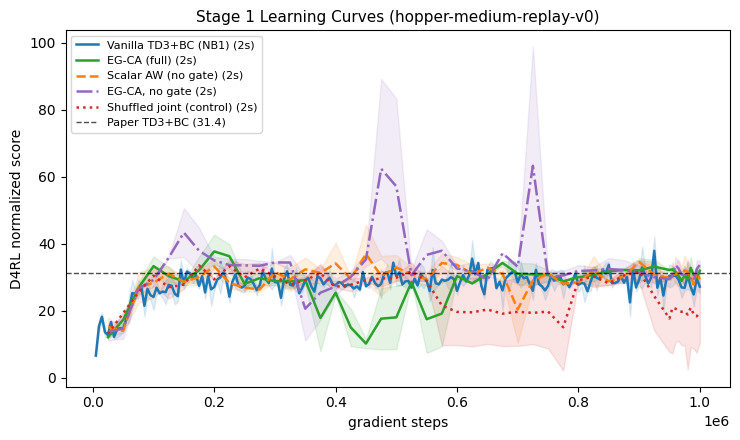

In [10]:
# Compute final-10 scores for Stage 1 variants and baseline
base_scores = finals(baseline_runs, [(STAGE1_TASK, s) for s in SEEDS], use_nb1=True)
st1_results = {}
for name in STAGE1_VARIANTS:
    st1_results[name] = finals(stage1_runs, [(name, s) for s in SEEDS], use_nb1=False)

rows = []
rows.append({
    "Variant": "Vanilla TD3+BC (NB1)",
    "Seeds": len(base_scores),
    "Mean": np.mean(base_scores) if base_scores else np.nan,
    "Std": np.std(base_scores) if base_scores else np.nan,
})
for name, sc in st1_results.items():
    rows.append({
        "Variant": name,
        "Seeds": len(sc),
        "Mean": np.mean(sc) if sc else np.nan,
        "Std": np.std(sc) if sc else np.nan,
    })
df_st1 = pd.DataFrame(rows).set_index("Variant")

# Pre-registered decision rule evaluation
full_sc = st1_results.get("EG-CA (full)", [])
m_full = np.mean(full_sc) if full_sc else -np.inf
m_base = np.mean(base_scores) if base_scores else np.nan
min_full = np.min(full_sc) if full_sc else -np.inf
max_base = np.max(base_scores) if base_scores else np.inf

STAGE1_GO = bool(m_full >= m_base + 3.0 and min_full > max_base) if (full_sc and base_scores) else False

print("=" * 60)
print(f"STAGE 1 DECISION RULE: {'*** GO TO STAGE 2 ***' if STAGE1_GO else '*** STOP (NEGATIVE RESULT) ***'}")
print(f"Condition 1: mean(EG-CA full) [{m_full:.2f}] >= mean(TD3+BC) [{m_base:.2f}] + 3.0 -> {m_full >= m_base + 3.0}")
print(f"Condition 2: min(EG-CA seeds) [{min_full:.2f}] > max(TD3+BC seeds) [{max_base:.2f}] -> {min_full > max_base}")
print("=" * 60)

# Hypotheses deltas (C1 - C4)
m_aw = np.mean(st1_results.get("Scalar AW (no gate)", [np.nan]))
m_nogate = np.mean(st1_results.get("EG-CA, no gate", [np.nan]))
m_shuff = np.mean(st1_results.get("Shuffled joint (control)", [np.nan]))

deltas = {
    "C1: EG-CA (full) vs Vanilla TD3+BC": m_full - m_base,
    "C2: EG-CA no gate vs Scalar AW (Coord Attribution Claim)": m_nogate - m_aw,
    "C3: EG-CA full vs EG-CA no gate (Disagreement Gate Effect)": m_full - m_nogate,
    "C4: EG-CA full vs Shuffled Joint (Joint Attribution Causality)": m_full - m_shuff,
}
print("\n--- Orthogonal Mechanism Deltas ---")
for k, v in deltas.items():
    print(f"{k:65s}: {v:+.2f}")

df_st1.round(2).to_csv("figures/stage1_table.csv")

# Plot Stage 1 curves on a single axis
fig, ax = plt.subplots(figsize=(7.5, 4.5))
palette = {
    "Vanilla TD3+BC (NB1)": ("tab:blue", "-", [load_run(baseline_runs[(STAGE1_TASK, s)], True) for s in SEEDS]),
    "EG-CA (full)": ("tab:green", "-", [load_run(stage1_runs[("EG-CA (full)", s)], False) for s in SEEDS]),
    "Scalar AW (no gate)": ("tab:orange", "--", [load_run(stage1_runs[("Scalar AW (no gate)", s)], False) for s in SEEDS]),
    "EG-CA, no gate": ("tab:purple", "-.", [load_run(stage1_runs[("EG-CA, no gate", s)], False) for s in SEEDS]),
    "Shuffled joint (control)": ("tab:red", ":", [load_run(stage1_runs[("Shuffled joint (control)", s)], False) for s in SEEDS]),
}
for label, (color, ls, rs_raw) in palette.items():
    rs = [r for r in rs_raw if r is not None]
    if rs:
        steps, y = curve(rs)
        ax.plot(steps, y.mean(0), label=f"{label} ({len(rs)}s)", color=color, linestyle=ls, linewidth=1.8)
        ax.fill_between(steps, y.mean(0) - y.std(0), y.mean(0) + y.std(0), color=color, alpha=0.12)
ax.axhline(PAPER_SCORES[STAGE1_TASK][0], ls="--", c="k", lw=1, alpha=0.7, label=f"Paper TD3+BC ({PAPER_SCORES[STAGE1_TASK][0]})")
ax.set_title(f"Stage 1 Learning Curves ({STAGE1_TASK})", fontsize=11)
ax.set_xlabel("gradient steps")
ax.set_ylabel("D4RL normalized score")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("figures/stage1_curves.png", dpi=150)
df_st1.round(2)

## 5. Stage 1 Mechanism Diagnostics (Weight Spread & Gate Activity)

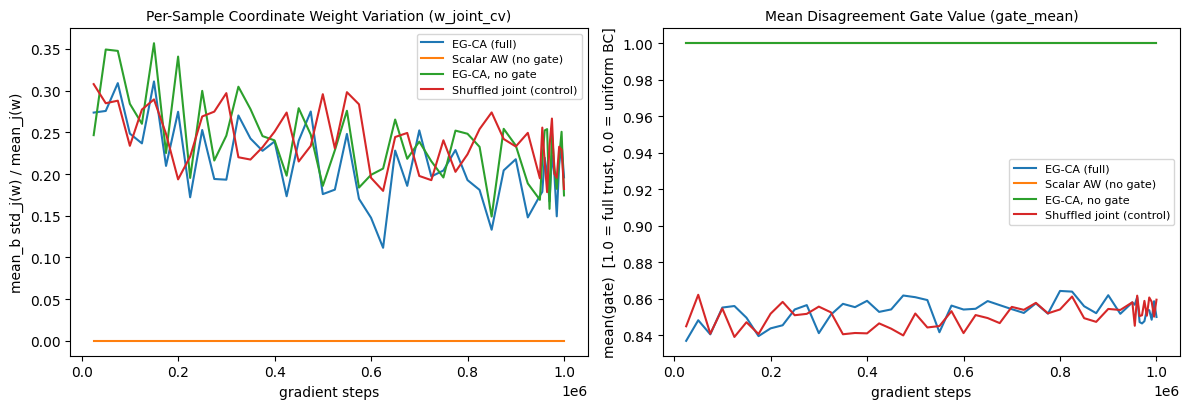

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for name in STAGE1_VARIANTS:
    rs = [r for r in (load_run(stage1_runs[(name, s)], False) for s in SEEDS) if r is not None and "diag_w_joint_cv" in r]
    if rs:
        steps, y_joint = curve(rs, "diag_w_joint_cv")
        ax1.plot(steps, y_joint.mean(0), label=name)
        steps, y_gate = curve(rs, "diag_gate_mean")
        ax2.plot(steps, y_gate.mean(0), label=name)

ax1.set_title("Per-Sample Coordinate Weight Variation (w_joint_cv)", fontsize=10)
ax1.set_xlabel("gradient steps")
ax1.set_ylabel("mean_b std_j(w) / mean_j(w)")
ax1.legend(fontsize=8)

ax2.set_title("Mean Disagreement Gate Value (gate_mean)", fontsize=10)
ax2.set_xlabel("gradient steps")
ax2.set_ylabel("mean(gate)  [1.0 = full trust, 0.0 = uniform BC]")
ax2.legend(fontsize=8)

fig.tight_layout()
fig.savefig("figures/stage1_diagnostics.png", dpi=150)

## 6. Stage 2 Execution (`halfcheetah` & `walker2d` Medium-Replay)

Executes **only if** Stage 1 satisfied the pre-registered decision rule (`STAGE1_GO = True`), or if explicitly forced via `FORCE_STAGE2 = True`.

In [ ]:
FORCE_STAGE2 = False
if SMOKE:
    FORCE_STAGE2 = True  # under smoke test, run both stages to verify all cells

if STAGE1_GO or FORCE_STAGE2:
    print(f"Executing Stage 2 ({len(stage2_runs)} runs across {STAGE2_TASKS})...")
    train_new.live(list(stage2_runs.values()), jobs=min(JOBS, 4))
else:
    print("Stage 1 decision rule evaluated to STOP. Skipping Stage 2 to conserve compute.")
    print("To override and run Stage 2 anyway, set FORCE_STAGE2 = True and re-run this cell.")

## 7. Final 3-Task Comparison Table & Curves (TD3+BC vs. EG-CA)

,Paper TD3+BC,Vanilla TD3+BC (NB1),Vanilla Std,EG-CA TD3+BC,EG-CA Std,Gain vs Baseline
Task,,,,,,
hopper-medium-replay-v0,31.4,28.31,0.46,30.84,0.74,2.53
halfcheetah-medium-replay-v0,43.3,43.23,0.00,NaN,NaN,NaN
walker2d-medium-replay-v0,25.2,33.28,9.21,NaN,NaN,NaN


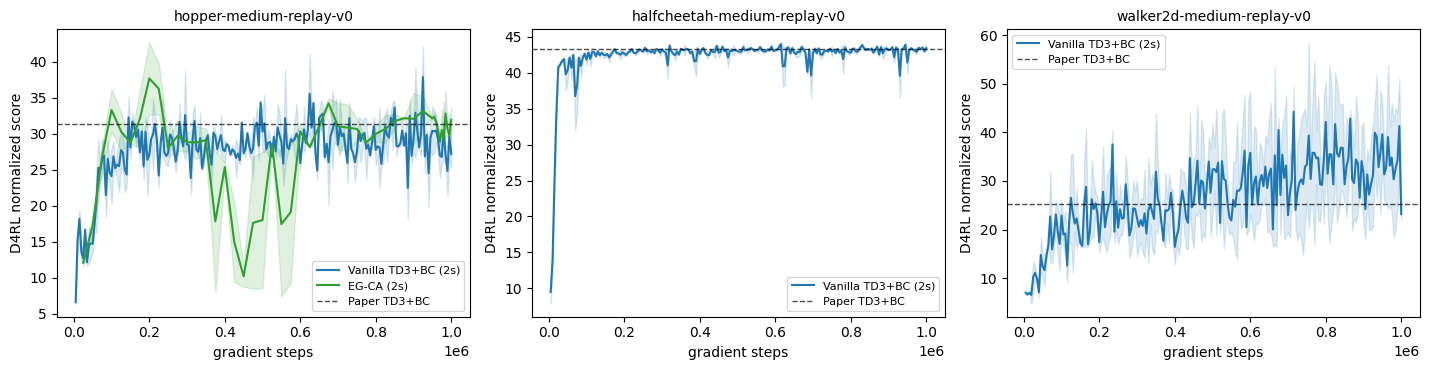

In [12]:
summary_rows = []
for t in ALL_TASKS:
    base_sc = finals(baseline_runs, [(t, s) for s in SEEDS], use_nb1=True)
    if t == STAGE1_TASK:
        egca_sc = finals(stage1_runs, [("EG-CA (full)", s) for s in SEEDS], use_nb1=False)
    else:
        egca_sc = finals(stage2_runs, [(t, s) for s in SEEDS], use_nb1=False)

    summary_rows.append({
        "Task": t,
        "Paper TD3+BC": PAPER_SCORES[t][0],
        "Vanilla TD3+BC (NB1)": np.mean(base_sc) if base_sc else np.nan,
        "Vanilla Std": np.std(base_sc) if base_sc else np.nan,
        "EG-CA TD3+BC": np.mean(egca_sc) if egca_sc else np.nan,
        "EG-CA Std": np.std(egca_sc) if egca_sc else np.nan,
        "Gain vs Baseline": (np.mean(egca_sc) - np.mean(base_sc)) if (egca_sc and base_sc) else np.nan,
    })

df_final = pd.DataFrame(summary_rows).set_index("Task")
df_final.round(2).to_csv("figures/final_table.csv")

# 3-Task Learning Curves Grid
fig, axes = plt.subplots(1, len(ALL_TASKS), figsize=(4.8 * len(ALL_TASKS), 3.8), squeeze=False)
for j, t in enumerate(ALL_TASKS):
    ax = axes[0, j]
    rs_base = [load_run(baseline_runs[(t, s)], True) for s in SEEDS]
    rs_base = [r for r in rs_base if r is not None]
    if rs_base:
        steps, y = curve(rs_base)
        ax.plot(steps, y.mean(0), label=f"Vanilla TD3+BC ({len(rs_base)}s)", color="tab:blue")
        ax.fill_between(steps, y.mean(0) - y.std(0), y.mean(0) + y.std(0), color="tab:blue", alpha=0.15)

    if t == STAGE1_TASK:
        rs_egca = [load_run(stage1_runs[("EG-CA (full)", s)], False) for s in SEEDS]
    else:
        rs_egca = [load_run(stage2_runs[(t, s)], False) for s in SEEDS]
    rs_egca = [r for r in rs_egca if r is not None]
    if rs_egca:
        steps, y = curve(rs_egca)
        ax.plot(steps, y.mean(0), label=f"EG-CA ({len(rs_egca)}s)", color="tab:green")
        ax.fill_between(steps, y.mean(0) - y.std(0), y.mean(0) + y.std(0), color="tab:green", alpha=0.15)

    ax.axhline(PAPER_SCORES[t][0], ls="--", c="k", lw=1, alpha=0.7, label="Paper TD3+BC")
    ax.set_title(t, fontsize=10)
    ax.set_xlabel("gradient steps")
    ax.set_ylabel("D4RL normalized score")
    ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig("figures/final_curves.png", dpi=150)
df_final.round(2)